возьмём задачу с известным ответом: $a=1$, $b=c=0$, $\lambda=2$ и точное решение $f(x)=e^{-x^2}$. Тогда правая часть
$$g(x) = -\bigl(f'' - 2f\bigr) = (4-4x^2)\,e^{-x^2}.$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from Chern import ChernovSolver

## 1. Задаём задачу

Коэффициенты — функции от numpy-массива. Константы можно задавать как `lambda x: 1.0`.

In [2]:
a = lambda x: 1.0
b = lambda x: 0.0
c = lambda x: 0.0
g = lambda x: (4 - 4 * x**2) * np.exp(-x**2)
lam = 2.0                                  # нужно lam > sup|c|

f_exact = lambda x: np.exp(-x**2)          # для проверки

## 2. Решение на сетке

В отличие от Монте-Карло, метод сразу даёт решение на всей сетке $[x_{\min}, x_{\max}]$ с шагом `dx`. Вне окна функция продолжается нулём, поэтому окно берут с запасом: решение у краёв должно быть пренебрежимо мало.

`n` — число множителей в $(S(t/n))^n$, от него зависит точность. `T` (верхний предел по $t$) подбирается автоматически.

T = 6.91, точек по x: 321
наибольшая ошибка: 0.0006354887113988461


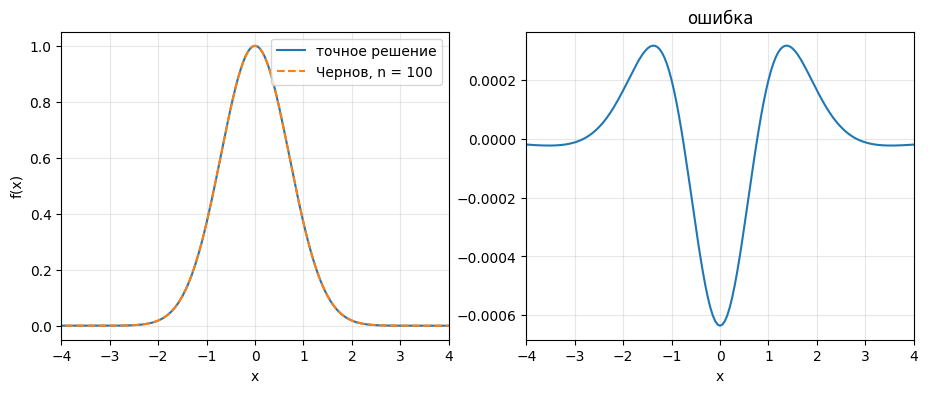

In [3]:
solver = ChernovSolver(a, b, c, g, lam, x_min=-8, x_max=8, dx=0.05, n=100)
f = solver.solve()
x = solver.x_grid

print(f"T = {solver.T:.2f}, точек по x: {solver.n_points}")
print("наибольшая ошибка:", np.max(np.abs(f - f_exact(x))))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(x, f_exact(x), label="точное решение")
ax1.plot(x, f, "--", label="Чернов, n = 100")
ax1.set_xlim(-4, 4); ax1.set_xlabel("x"); ax1.set_ylabel("f(x)")
ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(x, f - f_exact(x))
ax2.set_xlim(-4, 4); ax2.set_xlabel("x"); ax2.set_title("ошибка"); ax2.grid(alpha=0.3)
plt.show()

## 3. Значение в одной точке

Решение задано в узлах сетки; между узлами его можно интерполировать.

In [4]:
x0 = 0.3
print(f"Чернов:  {np.interp(x0, x, f):.5f}")
print(f"точное:  {f_exact(x0):.5f}")

Чернов:  0.91343
точное:  0.91393


## 5. Быстрый вариант: `solve_streaming`

`solve()` строит композицию $(S(t/n))^n g$ заново для каждого узла по $t$. `solve_streaming()` делает одну цепочку $u_{k+1} = S(\tau)u_k$ с шагом $\tau = T/n_{\text{steps}}$ — это в разы дешевле. Сетка по $t$ при этом равномерная, поэтому на задачах с резким поведением у $t=0$ (высокие частоты) он может проиграть `solve()`. Подробнее — в `streaming.ipynb`.

In [7]:
import time

t0 = time.perf_counter()
s = ChernovSolver(a, b, c, g, lam, x_min=-8, x_max=8, dx=0.05)
f_s = s.solve_streaming(n_steps=2000)
print(f"ошибка {np.max(np.abs(f_s - f_exact(s.x_grid))):.2e}, время {time.perf_counter() - t0:.1f} с")

ошибка 7.60e-04, время 0.3 с


## 6. Шаблон для своей задачи

Подставьте свои $a, b, c, g, \lambda$. Что проверить:
1. $\lambda > \sup|c|$ и $a(x) > 0$ — иначе конструктор выдаст ошибку;
2. окно `[x_min, x_max]` с запасом: решение у краёв близко к нулю;
3. результат при `n` и `2n` — разница даёт оценку ошибки (п. 4).

Здесь та же задача, что в шаблоне `montecarlo/example.ipynb`; Монте-Карло там дал $f(0) \approx 0.4123 \pm 0.0022$.

n = 50   f(0) ≈ 0.4103


n = 100  f(0) ≈ 0.4107


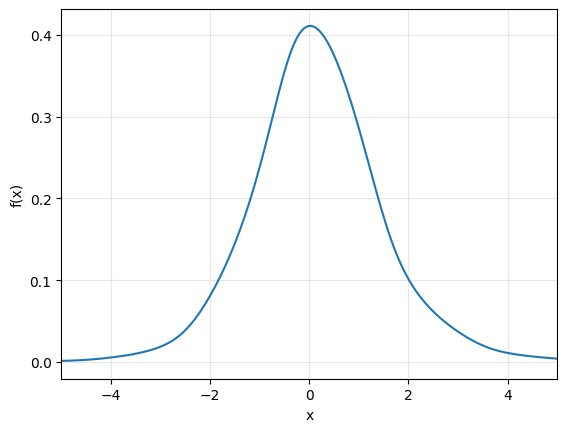

In [7]:
a = lambda x: 1 + 0.3 * np.sin(np.pi * x)     # a(x) > 0
b = lambda x: 0.4 * np.cos(np.pi * x)
c = lambda x: 0.3 * np.tanh(x)
g = lambda x: np.exp(-x**2)
lam = 1.5                                     # > sup|c| = 0.3

for n in (50, 100):
    s = ChernovSolver(a, b, c, g, lam, x_min=-8, x_max=8, dx=0.05, n=n)
    f = s.solve()
    print(f"n = {n:<4} f(0) ≈ {np.interp(0.0, s.x_grid, f):.4f}")

plt.plot(s.x_grid, f)
plt.xlim(-5, 5); plt.xlabel("x"); plt.ylabel("f(x)"); plt.grid(alpha=0.3)
plt.show()